# Task 1: MLP vs CNN

We train an MLP and a CNN on CIFAR-10, with a small hyperparameter search for each, and compare them.
Every model is trained 5 times (5-fold cross-validation). Results and models are saved in `out/`, so the notebook
can be re-run without training everything again.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from joblib import Parallel, delayed

from models import MLP, CNN
from plots import *
from utils import *

## Looking at the data

In [2]:
X_train, y_train, X_test, y_test = load_cifar()
print('train:', X_train.shape, X_train.dtype)
print('test: ', X_test.shape)
print('pixel values go from', X_train.min().item(), 'to', X_train.max().item())

train: torch.Size([50000, 3, 32, 32]) torch.uint8
test:  torch.Size([10000, 3, 32, 32])
pixel values go from 0 to 255


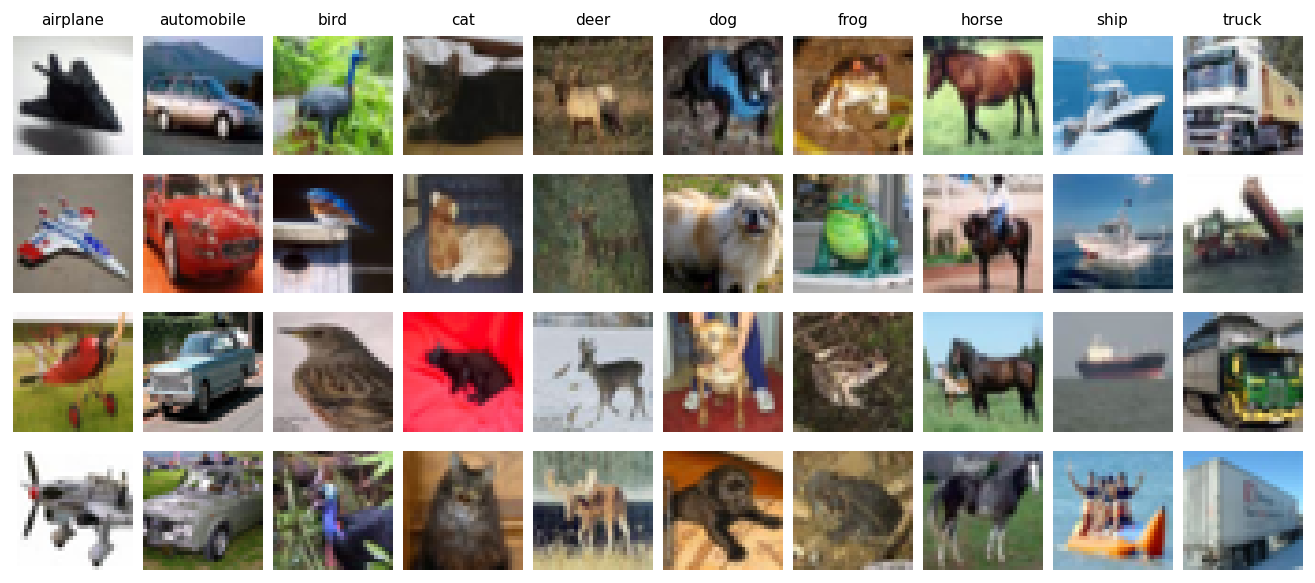

In [3]:
# 4 training images of each class
fig, axes = plt.subplots(4, 10, figsize=(10, 4.4))
for c in range(10):
    idx = (y_train == c).nonzero()[:4, 0]
    for r in range(4):
        axes[r, c].imshow(X_train[idx[r]].permute(1, 2, 0))
        axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c])
plt.show()

In [4]:
# the classes are balanced
print('train:', np.bincount(y_train.numpy()))
print('test: ', np.bincount(y_test.numpy()))

train: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
test:  [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [5]:
# mean and std of each colour channel, used to normalize the images (MEAN and STD in utils.py)
for c, colour in enumerate(['red', 'green', 'blue']):
    channel = X_train[:, c].float() / 255
    print(colour, round(channel.mean().item(), 4), round(channel.std().item(), 4))

red 0.4914 0.247
green 0.4822 0.2435
blue 0.4465 0.2616


In [6]:
# 5 folds of 10,000 images: each model is trained 5 times, every time validated on a different fold
folds = make_folds(y_train)
for k in range(N_FOLDS):
    train_idx, val_idx = folds[k]
    print('fold', k, '- train:', len(train_idx), ' val:', len(val_idx), ' val per class:',
          np.bincount(y_train[val_idx].numpy()))

fold 0 - train: 40000  val: 10000  val per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 1 - train: 40000  val: 10000  val per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 2 - train: 40000  val: 10000  val per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 3 - train: 40000  val: 10000  val per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 4 - train: 40000  val: 10000  val per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## Hyperparameter search
For each model, 2 sizes and 3 peak learning rates (10 epochs each).

In [7]:
configs = {}
for hidden in [[512, 256], [1024, 512, 256]]:
    for lr in [3e-4, 1e-3, 3e-3]:
        name = 'mlp_' + '-'.join(str(h) for h in hidden) + '_' + str(lr)
        configs[name] = {'model_class': MLP, 'model_args': {'hidden': hidden}, 'lr': lr}
for width in [16, 32]:
    for lr in [1e-3, 3e-3, 1e-2]:
        name = f'cnn_{width}-{2 * width}-{4 * width}_{lr}'
        configs[name] = {'model_class': CNN, 'model_args': {'width': width}, 'lr': lr}
for name in configs:
    print(name)

mlp_512-256_0.0003
mlp_512-256_0.001
mlp_512-256_0.003
mlp_1024-512-256_0.0003
mlp_1024-512-256_0.001
mlp_1024-512-256_0.003
cnn_16-32-64_0.001
cnn_16-32-64_0.003
cnn_16-32-64_0.01
cnn_32-64-128_0.001
cnn_32-64-128_0.003
cnn_32-64-128_0.01


In [8]:
# train the folds that are not saved yet, 4 at a time (about 4 hours the first time)
jobs = []
for name in configs:
    for fold in range(N_FOLDS):
        if not os.path.exists(results_path(name, fold)):
            jobs.append(delayed(train_fold)(name, fold, **configs[name]))
print(len(jobs), 'folds to train')
if jobs:
    Parallel(n_jobs=N_JOBS, verbose=10)(jobs)

0 folds to train


In [9]:
# load what train_fold saved: for each model a list of 5 dicts, one per fold
results = {}
for name in configs:
    results[name] = load_results(name)
results['mlp_512-256_0.0003'][0].keys()

dict_keys(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'epoch_time', 'test_loss', 'test_acc', 'test_pred', 'n_params'])

In [10]:
for name, runs in results.items():
    print(f"{name:25s} val acc {mean_sd(last(runs, 'val_acc'))}   test acc {mean_sd(last(runs, 'test_acc'))}")

mlp_512-256_0.0003        val acc 55.6 (0.5)   test acc 55.5 (0.2)
mlp_512-256_0.001         val acc 56.1 (0.6)   test acc 55.7 (0.2)
mlp_512-256_0.003         val acc 54.1 (0.3)   test acc 54.5 (0.4)
mlp_1024-512-256_0.0003   val acc 56.7 (0.4)   test acc 56.4 (0.3)
mlp_1024-512-256_0.001    val acc 56.5 (0.5)   test acc 56.5 (0.2)
mlp_1024-512-256_0.003    val acc 54.8 (0.5)   test acc 55.0 (0.1)
cnn_16-32-64_0.001        val acc 76.3 (0.5)   test acc 75.7 (0.5)
cnn_16-32-64_0.003        val acc 78.3 (0.4)   test acc 77.9 (0.4)
cnn_16-32-64_0.01         val acc 78.1 (0.5)   test acc 77.7 (0.5)
cnn_32-64-128_0.001       val acc 79.9 (0.4)   test acc 79.3 (0.2)
cnn_32-64-128_0.003       val acc 81.4 (0.2)   test acc 81.0 (0.3)
cnn_32-64-128_0.01        val acc 80.7 (0.3)   test acc 80.4 (0.5)


In [11]:
rows = []
for name, runs in results.items():
    model, widths, lr = name.split('_')
    rows.append({'model': model.upper(), 'widths': widths, 'peak lr': lr,
                 'params (M)': f"{runs[0]['n_params'] / 1e6:.2f}",
                 'val acc': mean_sd(last(runs, 'val_acc')),
                 'final val loss': mean_sd(last(runs, 'val_loss'), scale=1, decimals=3),
                 's/epoch (1 thread)': mean_sd([np.mean(r['epoch_time']) for r in runs], scale=1, decimals=0)})
hp = pd.DataFrame(rows, index=list(results))
hp['mean val acc'] = [last(runs, 'val_acc').mean() for runs in results.values()]
hp

,model,widths,peak lr,params (M),val acc,final val loss,s/epoch (1 thread),mean val acc
mlp_512-256_0.0003,MLP,512-256,0.0003,1.71,55.6 (0.5),1.305 (0.017),23 (0),0.55616
mlp_512-256_0.001,MLP,512-256,0.001,1.71,56.1 (0.6),1.381 (0.017),22 (2),0.56076
mlp_512-256_0.003,MLP,512-256,0.003,1.71,54.1 (0.3),1.444 (0.025),23 (2),0.54068
mlp_1024-512-256_0.0003,MLP,1024-512-256,0.0003,3.81,56.7 (0.4),1.340 (0.027),65 (3),0.56706
mlp_1024-512-256_0.001,MLP,1024-512-256,0.001,3.81,56.5 (0.5),1.534 (0.031),51 (7),0.56530
mlp_1024-512-256_0.003,MLP,1024-512-256,0.003,3.81,54.8 (0.5),1.485 (0.019),44 (0),0.54844
cnn_16-32-64_0.001,CNN,16-32-64,0.001,0.29,76.3 (0.5),0.702 (0.011),55 (3),0.76314
cnn_16-32-64_0.003,CNN,16-32-64,0.003,0.29,78.3 (0.4),0.702 (0.013),54 (1),0.78260
cnn_16-32-64_0.01,CNN,16-32-64,0.01,0.29,78.1 (0.5),0.844 (0.021),60 (5),0.78060
cnn_32-64-128_0.001,CNN,32-64-128,0.001,0.62,79.9 (0.4),0.630 (0.012),115 (6),0.79878


In [12]:
best_mlp = hp[hp.model == 'MLP']['mean val acc'].idxmax()
best_cnn = hp[hp.model == 'CNN']['mean val acc'].idxmax()
print('best MLP:', best_mlp)
print('best CNN:', best_cnn)

# save the choice, the other notebooks use these two models
best = {'mlp': {'name': best_mlp, 'hidden': configs[best_mlp]['model_args']['hidden'], 'lr': configs[best_mlp]['lr']},
        'cnn': {'name': best_cnn, 'width': configs[best_cnn]['model_args']['width'], 'lr': configs[best_cnn]['lr']}}
with open('out/best.json', 'w') as f:
    json.dump(best, f)
save_table('hp', hp.drop(columns='mean val acc').set_index('model'))

best MLP: mlp_1024-512-256_0.0003
best CNN: cnn_32-64-128_0.003


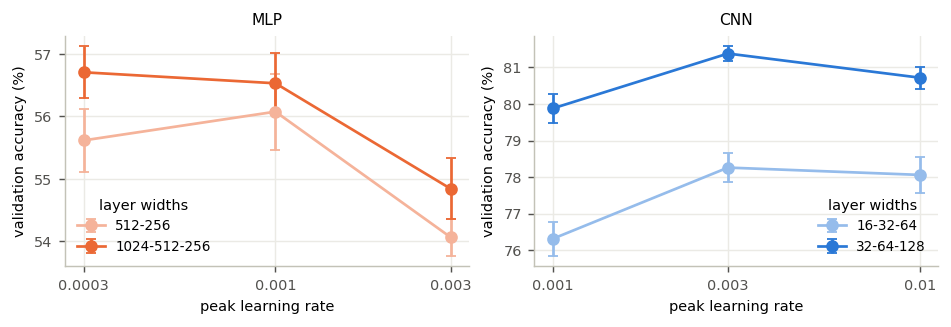

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4))
search = [(axes[0], 'mlp', ['512-256', '1024-512-256'], [3e-4, 1e-3, 3e-3]),
          (axes[1], 'cnn', ['16-32-64', '32-64-128'], [1e-3, 3e-3, 1e-2])]
for ax, model, sizes, lrs in search:
    for size, amount in zip(sizes, [0.5, 0]):
        acc = np.array([last(results[f'{model}_{size}_{lr}'], 'val_acc') for lr in lrs]) * 100
        ax.errorbar(lrs, acc.mean(1), acc.std(1, ddof=1), marker='o', capsize=3, color=lighter(COLORS[model], amount),
                    label=size)
    ax.set(xscale='log', xlabel='peak learning rate', ylabel='validation accuracy (%)', title=model.upper())
    ax.set_xticks(lrs, [str(lr) for lr in lrs])
    ax.minorticks_off()
    ax.legend(title='layer widths')
save_fig(fig, 'hp')

## The two selected models

In [14]:
print(MLP(best['mlp']['hidden']))
print(CNN(best['cnn']['width']))

MLP(
  (layers): ModuleList(
    (0): Linear(in_features=3072, out_features=1024, bias=True)
    (1): Linear(in_features=1024, out_features=512, bias=True)
    (2): Linear(in_features=512, out_features=256, bias=True)
  )
  (out): Linear(in_features=256, out_features=10, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)
CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_f

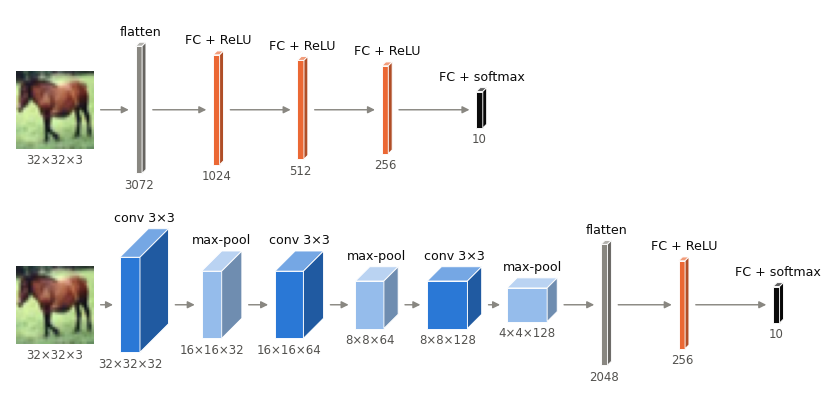

In [15]:
horse = X_train[(y_train == 7).nonzero()[0, 0]]
mlp_layers = [(3072, 'flatten', GRAY)]
for h in best['mlp']['hidden']:
    mlp_layers.append((h, 'FC + ReLU', COLORS['mlp']))
mlp_layers.append((10, 'FC + softmax', BLACK))
draw_architecture('arch', [mlp_layers, cnn_layers(best['cnn']['width'])], horse)

## Size, speed and memory
Measured on one batch of 128 images with 4 threads. The time changes with whatever else the laptop is doing,
so we measure once and save it.

In [16]:
bench = {}
if os.path.exists('out/benchmark.json'):
    with open('out/benchmark.json') as f:
        bench = json.load(f)
if best_mlp not in bench:
    bench[best_mlp] = benchmark(MLP(best['mlp']['hidden']), X_train, y_train)
if best_cnn not in bench:
    bench[best_cnn] = benchmark(CNN(best['cnn']['width']), X_train, y_train)
with open('out/benchmark.json', 'w') as f:
    json.dump(bench, f, indent=1)
pd.DataFrame([bench[best_mlp], bench[best_cnn]], index=['MLP', 'CNN'])

,params,weights_mb,adam_mb,activations_mb,epoch_seconds
MLP,3805450,14.516640,43.549919,2.375000,11.883219
CNN,620810,2.368202,7.104607,78.628418,32.400906


In [17]:
summary = pd.DataFrame(index=['MLP', 'CNN'])
summary['val acc'] = [mean_sd(last(results[n], 'val_acc')) for n in [best_mlp, best_cnn]]
summary['test acc'] = [mean_sd(last(results[n], 'test_acc')) for n in [best_mlp, best_cnn]]
summary['params (M)'] = [bench[n]['params'] / 1e6 for n in [best_mlp, best_cnn]]
summary['s / epoch'] = [bench[n]['epoch_seconds'] for n in [best_mlp, best_cnn]]
summary['memory (MB)'] = [bench[n]['weights_mb'] + bench[n]['adam_mb'] + bench[n]['activations_mb']
                          for n in [best_mlp, best_cnn]]
summary

,val acc,test acc,params (M),s / epoch,memory (MB)
MLP,56.7 (0.4),56.4 (0.3),3.80545,11.883219,60.441559
CNN,81.4 (0.2),81.0 (0.3),0.62081,32.400906,88.101227


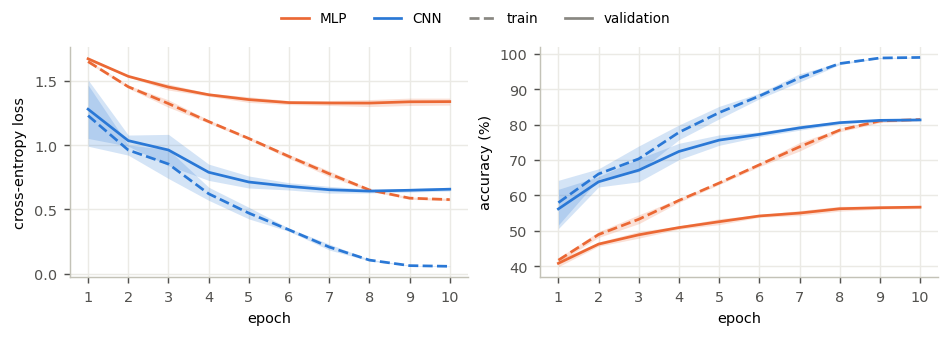

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
plot_curves(axes, {'MLP': (results[best_mlp], COLORS['mlp']), 'CNN': (results[best_cnn], COLORS['cnn'])})
save_fig(fig, 'curves')

## What the weights look like

In [19]:
# load the fold-1 models that train_fold saved
mlp = load_model(best_mlp, MLP, configs[best_mlp]['model_args'])
cnn = load_model(best_cnn, CNN, configs[best_cnn]['model_args'])
W = mlp.layers[0].weight.detach()
print('MLP first layer:', W.shape)
print('CNN first layer:', cnn.conv1.weight.shape)

MLP first layer: torch.Size([1024, 3072])
CNN first layer: torch.Size([32, 3, 3, 3])


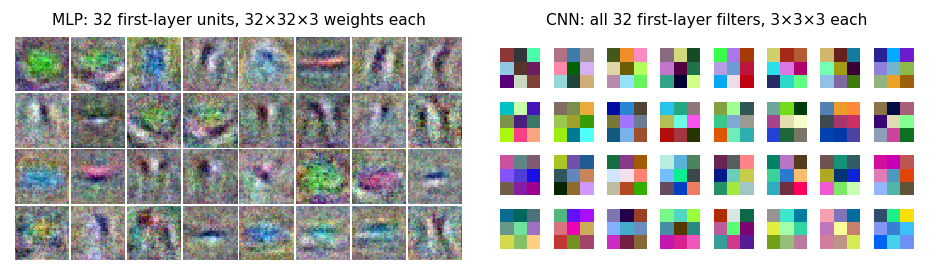

In [20]:
top32 = W.norm(dim=1).argsort(descending=True)[:32]  # the units with the largest weights
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2))
show_tiles(axes[0], W[top32].view(-1, 3, 32, 32))
show_tiles(axes[1], cnn.conv1.weight.detach())
axes[0].set_title('MLP: 32 first-layer units, 32×32×3 weights each')
axes[1].set_title(f'CNN: all {len(cnn.conv1.weight)} first-layer filters, 3×3×3 each')
save_fig(fig, 'weights')

In [21]:
# feature maps of a test horse after each conv (before pooling): the 8 most active ones
j = (y_test == 7).nonzero()[0, 0].item()
x = prepare(X_test[j:j + 1])
with torch.no_grad():
    a1 = F.relu(cnn.bn1(cnn.conv1(x)))
    a2 = F.relu(cnn.bn2(cnn.conv2(cnn.pool(a1))))
    a3 = F.relu(cnn.bn3(cnn.conv3(cnn.pool(a2))))
print(a1.shape, a2.shape, a3.shape)

torch.Size([1, 32, 32, 32]) torch.Size([1, 64, 16, 16]) torch.Size([1, 128, 8, 8])


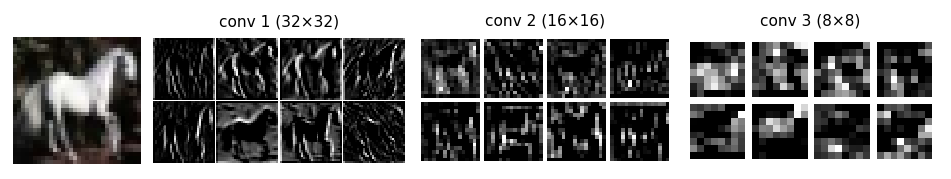

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(7.2, 1.6), gridspec_kw={'width_ratios': [1, 2, 2, 2]})
axes[0].imshow(X_test[j].permute(1, 2, 0))
axes[0].axis('off')
for i, a in enumerate([a1, a2, a3]):
    a = a[0]
    top8 = a.mean((1, 2)).argsort(descending=True)[:8]
    show_tiles(axes[i + 1], a[top8, None], 4)
    axes[i + 1].set_title(f'conv {i + 1} ({a.shape[-1]}×{a.shape[-1]})')
save_fig(fig, 'featuremaps')

## Shuffling the pixels
One fixed random permutation of the 1,024 pixel positions, the same for every image. The MLP should not care,
but the CNN loses the neighbourhoods its 3x3 filters look at.

In [23]:
shuffled_configs = {}
for name in [best_mlp, best_cnn]:
    config = configs[name].copy()
    config['data'] = 'shuffled'
    shuffled_configs[name + '_perm'] = config

jobs = []
for name in shuffled_configs:
    for fold in range(N_FOLDS):
        if not os.path.exists(results_path(name, fold)):
            jobs.append(delayed(train_fold)(name, fold, **shuffled_configs[name]))
print(len(jobs), 'folds to train')
if jobs:
    Parallel(n_jobs=N_JOBS, verbose=10)(jobs)

0 folds to train


In [24]:
shuffled = {}
for name in shuffled_configs:
    shuffled[name] = load_results(name)
    print(name, 'test acc', mean_sd(last(shuffled[name], 'test_acc')))

mlp_1024-512-256_0.0003_perm test acc 56.4 (0.2)
cnn_32-64-128_0.003_perm test acc 53.0 (0.3)


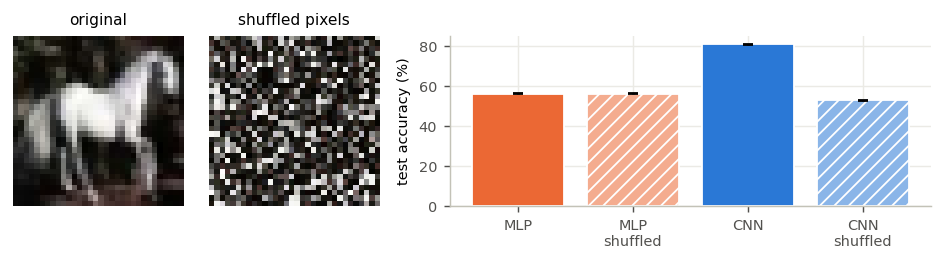

In [25]:
x = X_test[j:j + 1]
fig, axes = plt.subplots(1, 3, figsize=(7.2, 1.9), gridspec_kw={'width_ratios': [1, 1, 2.6]})
axes[0].imshow(x[0].permute(1, 2, 0))
axes[0].set_title('original')
axes[1].imshow(shuffle_pixels(x)[0].permute(1, 2, 0))
axes[1].set_title('shuffled pixels')
axes[0].axis('off')
axes[1].axis('off')

bars = [('MLP', results[best_mlp], COLORS['mlp'], False),
        ('MLP\nshuffled', shuffled[best_mlp + '_perm'], COLORS['mlp'], True),
        ('CNN', results[best_cnn], COLORS['cnn'], False),
        ('CNN\nshuffled', shuffled[best_cnn + '_perm'], COLORS['cnn'], True)]
for i, (label, runs, color, is_shuffled) in enumerate(bars):
    acc = last(runs, 'test_acc') * 100
    if is_shuffled:
        axes[2].bar(i, acc.mean(), 0.8, yerr=acc.std(ddof=1), capsize=3, color=lighter(color, 0.45), hatch='///',
                    edgecolor='white')
    else:
        axes[2].bar(i, acc.mean(), 0.8, yerr=acc.std(ddof=1), capsize=3, color=color, edgecolor='white')
axes[2].set_xticks(range(4), [b[0] for b in bars])
axes[2].set_ylabel('test accuracy (%)')
save_fig(fig, 'perm')

## Numbers for the report

In [26]:
numbers = {}
for prefix, name in [('mlp', best_mlp), ('cnn', best_cnn)]:
    runs, b = results[name], bench[name]
    numbers[prefix + 'Widths'] = hp.loc[name, 'widths']
    numbers[prefix + 'LR'] = hp.loc[name, 'peak lr']
    numbers[prefix + 'Val'] = mean_sd(last(runs, 'val_acc'))
    numbers[prefix + 'Test'] = mean_sd(last(runs, 'test_acc'))
    numbers[prefix + 'Perm'] = mean_sd(last(shuffled[name + '_perm'], 'test_acc'))
    numbers[prefix + 'Params'] = f"{b['params'] / 1e6:.2f}"
    numbers[prefix + 'Epoch'] = f"{b['epoch_seconds']:.0f}"
    numbers[prefix + 'Mem'] = f"{b['weights_mb'] + b['adam_mb'] + b['activations_mb']:.0f}"
    # CPU time of the whole search for this kind of model
    seconds = 0
    for other, other_runs in results.items():
        if other.startswith(prefix):
            seconds += sum(sum(r['epoch_time']) for r in other_runs)
    numbers[prefix + 'Tune'] = f'{seconds / 3600:.1f}'
save_numbers('t1', numbers)
numbers

{'mlpWidths': '1024-512-256',
 'mlpLR': '0.0003',
 'mlpVal': '56.7 (0.4)',
 'mlpTest': '56.4 (0.3)',
 'mlpPerm': '56.4 (0.2)',
 'mlpParams': '3.81',
 'mlpEpoch': '12',
 'mlpMem': '60',
 'mlpTune': '3.2',
 'cnnWidths': '32-64-128',
 'cnnLR': '0.003',
 'cnnVal': '81.4 (0.2)',
 'cnnTest': '81.0 (0.3)',
 'cnnPerm': '53.0 (0.3)',
 'cnnParams': '0.62',
 'cnnEpoch': '32',
 'cnnMem': '88',
 'cnnTune': '6.8'}